# Gaussian: data-space diagnostics

Figures only, using existing combined CSVs. Set `NUM_OBS` to 10 or 100 and select
`SUMMARY_DIMS`, then **Restart Kernel and Run All**. Both baseline and inference-only
are plotted; inference-only supports S=40/80, while baseline also supports S=20.

The overview shows all four diagnostics and three inference-error metrics. The final
section separates S, colors by M1–M12 source model, and places baseline on the left
and inference-only on the right. S=20 is shown for baseline alone.
All figures are embedded in this notebook.

In [1]:
from io import BytesIO
from pathlib import Path
import inspect
import sys

sys.dont_write_bytecode = True
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "examples/gaussian/config.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the model_comparison_new repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as NotebookImage, Markdown, display
from PIL import Image as PILImage
from examples.gaussian.analysis.plot import load_runs, plot_metric_grid, DIAGNOSTICS, KEYS, METRICS
from examples.gaussian.analysis.comparison_dataspace import output_root, result_root

NUM_OBS = 10
SUMMARY_DIMS = (20, 40, 80)
SOURCE_DIAGNOSTICS = ("l2", "density")  # Same columns as baseline_vs_standardization_n10.
SOURCE_SUMMARY_DIMS = tuple(sorted(SUMMARY_DIMS, reverse=True))

VARIANTS = ("baseline", "inference_only")
VARIANT_NAMES = {"baseline": "Baseline", "inference_only": "Inference-only"}
SUPPORTED = {(n, variant): dims for n in (10, 100)
             for variant, dims in (("baseline", (20, 40, 80)), ("inference_only", (40, 80)))}
ERROR_FLAGS = {"posterior_mmd": "posterior_error_positive",
               "logml": "logml_error_positive", "pmp": "pmp_error_positive"}
METRIC_NAMES = {"posterior_mmd": "Posterior MMD error",
                "logml": "Log10 marginal-likelihood error", "pmp": "PMP error"}
if NUM_OBS not in (10, 100):
    raise ValueError("NUM_OBS must be 10 or 100.")
if not SUMMARY_DIMS or len(set(SUMMARY_DIMS)) != len(SUMMARY_DIMS):
    raise ValueError("SUMMARY_DIMS must be nonempty and contain no duplicates.")
if not set(SUMMARY_DIMS) <= {20, 40, 80}:
    raise ValueError("Baseline supports S=20/40/80; inference_only supports S=40/80.")
if not set(SUMMARY_DIMS).intersection((40, 80)):
    raise ValueError("Include S=40 or S=80 to plot inference_only and paired comparisons.")
if not SOURCE_DIAGNOSTICS or len(set(SOURCE_DIAGNOSTICS)) != len(SOURCE_DIAGNOSTICS) or not set(SOURCE_DIAGNOSTICS) <= set(DIAGNOSTICS):
    raise ValueError(f"SOURCE_DIAGNOSTICS must select from {DIAGNOSTICS}.")
if not SOURCE_SUMMARY_DIMS or not set(SOURCE_SUMMARY_DIMS) <= set(SUMMARY_DIMS):
    raise ValueError("SOURCE_SUMMARY_DIMS must select from SUMMARY_DIMS.")
for function, parameters in ((load_runs, ("summary_dims", "result_dir")),
                             (plot_metric_grid, ("diagnostics", "output", "ylim", "color_by", "source_marker"))):
    if not set(parameters) <= set(inspect.signature(function).parameters):
        raise NotImplementedError(f"Unsupported plotting interface: {inspect.signature(function)}")


## Data loading and validation

Checks run silently on all ten combined CSVs: 2400 unique dataset/model rows per file,
required fields, saved error flags, original CSV values, and identical data-space
columns across S and variant for each n. Missing files or mismatches raise errors
with their paths or dataset keys. The plotting copies preserve inference errors and
calibration thresholds exactly.

In [2]:
def require_files(paths):
    missing = [str(path) for path in paths if not path.is_file()]
    if missing:
        raise FileNotFoundError("Missing saved inputs (no recomputation):\n" + "\n".join(missing))

def require_columns(frame, columns, path):
    missing = sorted(set(columns) - set(frame.columns))
    if missing:
        raise ValueError(f"{path}: missing columns {missing}")

paths = {}
for (n, variant), dims in SUPPORTED.items():
    for s in dims:
        relative = Path(f"comparison/n{n}/indirect_s{s}/data.csv")
        paths[n, variant, s] = {"combined": output_root(variant) / relative,
                                "original": result_root(variant) / relative}
require_files([path for inputs in paths.values() for path in inputs.values()])
required = (KEYS + list(ERROR_FLAGS.values()) + ["data_diagnostic_dim"]
            + [f"{prefix}{d}" for d in DIAGNOSTICS
               for prefix in ("data_d_", "data_rho_", "data_rho_low_", "data_high_surprise_")])
all_runs = {}
for (n, variant), dims in SUPPORTED.items():
    loaded = load_runs("indirect", n, summary_dims=dims, result_dir=output_root(variant))
    all_runs[n, variant] = loaded
    for label, frame in loaded.items():
        s = int(frame.summary_dim.iloc[0])
        inputs = paths[n, variant, s]
        require_columns(frame, required, inputs["combined"])
        if len(frame) != 2400 or frame.duplicated(KEYS).any():
            raise ValueError(f"{inputs['combined']}: expected 2400 unique dataset/model rows.")
        if (set(frame.source_model) != {f"m{i}" for i in range(1, 13)}
                or not frame.groupby("source_model").id.nunique().eq(50).all()):
            raise ValueError(f"{inputs['combined']}: expected 50 datasets for each of M1–M12.")
        numeric = [c for c in required if c not in KEYS + list(ERROR_FLAGS.values())
                   and not c.startswith("data_high_surprise_")]
        if not np.isfinite(frame[numeric].to_numpy(float)).all():
            raise ValueError(f"{inputs['combined']}: non-finite data-space diagnostic values.")
        for flag in ERROR_FLAGS.values():
            if not pd.api.types.is_bool_dtype(frame[flag]) or frame[flag].isna().any():
                raise ValueError(f"{inputs['combined']}: {flag} must contain saved booleans.")
        for diagnostic in DIAGNOSTICS:
            flag = f"data_high_surprise_{diagnostic}"
            pd.testing.assert_series_equal(frame[flag], frame[f"data_rho_{diagnostic}"].gt(1),
                                           check_names=False, check_exact=True,
                                           obj=f"{inputs['combined']}: {flag}")
        original = pd.read_csv(inputs["original"])
        require_columns(frame, original.columns, inputs["combined"])
        pd.testing.assert_frame_equal(
            original.set_index(KEYS).sort_index(),
            frame[original.columns].set_index(KEYS).sort_index(),
            check_exact=False, rtol=1e-12, atol=1e-12,
            obj=f"Original CSV columns preserved in {inputs['combined']}",
        )

for n in (10, 100):
    reference = all_runs[n, "baseline"]["S=D"].set_index(KEYS).sort_index()
    data_columns = sorted(c for c in reference if c.startswith("data_"))
    for (other_n, variant), loaded in all_runs.items():
        if other_n != n:
            continue
        for label, frame in loaded.items():
            current = frame.set_index(KEYS).sort_index()
            if not reference.index.equals(current.index):
                raise ValueError(f"Dataset/model keys differ: n={n}, {variant}, {label}.")
            require_columns(current, data_columns, f"n={n}, {variant}, {label}")
            pd.testing.assert_frame_equal(reference[data_columns], current[data_columns],
                                          check_exact=True,
                                          obj=f"Data-space columns: n={n}, {variant}, {label}")

selected_runs = {
    variant: {label: frame for label, frame in all_runs[NUM_OBS, variant].items()
              if int(frame.summary_dim.iloc[0]) in SUMMARY_DIMS}
    for variant in VARIANTS
}
# Compare the same simulated datasets; each variant retains its own inference errors.
for label in selected_runs["inference_only"]:
    baseline = selected_runs["baseline"][label].set_index(KEYS).sort_index()
    inference_only = selected_runs["inference_only"][label].set_index(KEYS).sort_index()
    pd.testing.assert_frame_equal(baseline[["gold_logml", "gold_pmp"]],
                                  inference_only[["gold_logml", "gold_pmp"]], check_exact=True)


In [3]:
def data_space_view(selected):
    mapping = {f"{prefix}{diagnostic}": f"data_{prefix}{diagnostic}"
               for diagnostic in DIAGNOSTICS for prefix in ("rho_", "rho_low_")}
    views = {}
    for label, original in selected.items():
        view = original.copy(deep=True)
        for destination, source in mapping.items():
            view[destination] = original[source].copy()
        unchanged = [column for column in original if column not in mapping]
        pd.testing.assert_frame_equal(original[unchanged], view[unchanged], check_exact=True)
        views[label] = view
    return views

data_runs = {variant: data_space_view(selected) for variant, selected in selected_runs.items()}

# Shared y limits include errors and threshold endpoints from both network settings.
axis_values = {}
for metric, (value, lower, upper, factor, _) in METRICS.items():
    axis_values[metric] = pd.concat([frame[[value, lower, upper]]
                                    for loaded in data_runs.values() for frame in loaded.values()]).to_numpy(float) * factor
log_lo, log_hi = axis_values["logml"].min(), axis_values["logml"].max()
pmp_extent = max(1.05, 1.04 * float(np.abs(axis_values["pmp"]).max()))
Y_AXIS = {
    "posterior_mmd": dict(yscale="linear", ylim=(0., max(1.5, np.ceil(axis_values["posterior_mmd"].max() * 4) / 4))),
    "logml": dict(yscale="symlog", linthresh=1., linscale=.9,
                  ylim=(-10. ** np.ceil(np.log10(max(1., -log_lo))),
                         10. ** np.ceil(np.log10(max(1., log_hi))))),
    "pmp": dict(yscale="linear", ylim=(-pmp_extent, pmp_extent)),
}


In [4]:
def figure_png(fig):
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
        return buffer.getvalue()

def show_overview(variant, metric):
    fig, _ = plot_metric_grid(data_runs[variant], metric, diagnostics=DIAGNOSTICS,
                              output=None, **Y_AXIS[metric])
    try:
        fig.suptitle(f"Data-space diagnostics — {VARIANT_NAMES[variant]}, n={NUM_OBS}",
                     y=1.015, fontsize=24)
        display(NotebookImage(data=figure_png(fig), format="png", width=1200))
    finally:
        plt.close(fig)

def source_panel(variant, metric, summary_dim):
    selected = {label: frame for label, frame in data_runs[variant].items()
                if int(frame.summary_dim.iloc[0]) == summary_dim}
    if len(selected) != 1:
        raise ValueError(f"Expected one {variant} S={summary_dim} run, found {len(selected)}.")
    run_label = next(iter(selected))
    fig, _ = plot_metric_grid(
        selected, metric, diagnostics=SOURCE_DIAGNOSTICS, color_by="source", source_marker="o",
        figsize=(14 if len(SOURCE_DIAGNOSTICS) <= 2 else 21.5, 20),
        output=None, **Y_AXIS[metric],
    )
    fig.suptitle(f"Data-space — {VARIANT_NAMES[variant]}, n={NUM_OBS}, {run_label}",
                 y=1.015, fontsize=24)
    return fig

def show_source_comparison(metric, summary_dim):
    panels = []
    try:
        for variant in VARIANTS:
            fig = source_panel(variant, metric, summary_dim)
            try:
                with PILImage.open(BytesIO(figure_png(fig))) as image:
                    panels.append(image.convert("RGB"))
            finally:
                plt.close(fig)
        with PILImage.new("RGB", (sum(p.width for p in panels) + 24,
                                  max(p.height for p in panels)), "white") as pair:
            x = 0
            for panel in panels:
                pair.paste(panel, (x, 0))
                x += panel.width + 24
            with BytesIO() as buffer:
                pair.save(buffer, format="PNG", dpi=(120, 120))
                display(NotebookImage(data=buffer.getvalue(), format="png", width=1400))
    finally:
        for panel in panels:
            panel.close()

def show_source_baseline(metric, summary_dim):
    fig = source_panel("baseline", metric, summary_dim)
    try:
        display(NotebookImage(data=figure_png(fig), format="png", width=800))
    finally:
        plt.close(fig)


## Baseline: data-space diagnostic overview

Rows are assumed M1–M4; columns are L2, L∞, density, and kernel MMD. Colors identify S.
Posterior MMD uses MMD units, logML uses the existing log10 conversion, and PMP keeps
its existing marker behavior. Plotting and smoothing follow `plot_metric_grid()`.

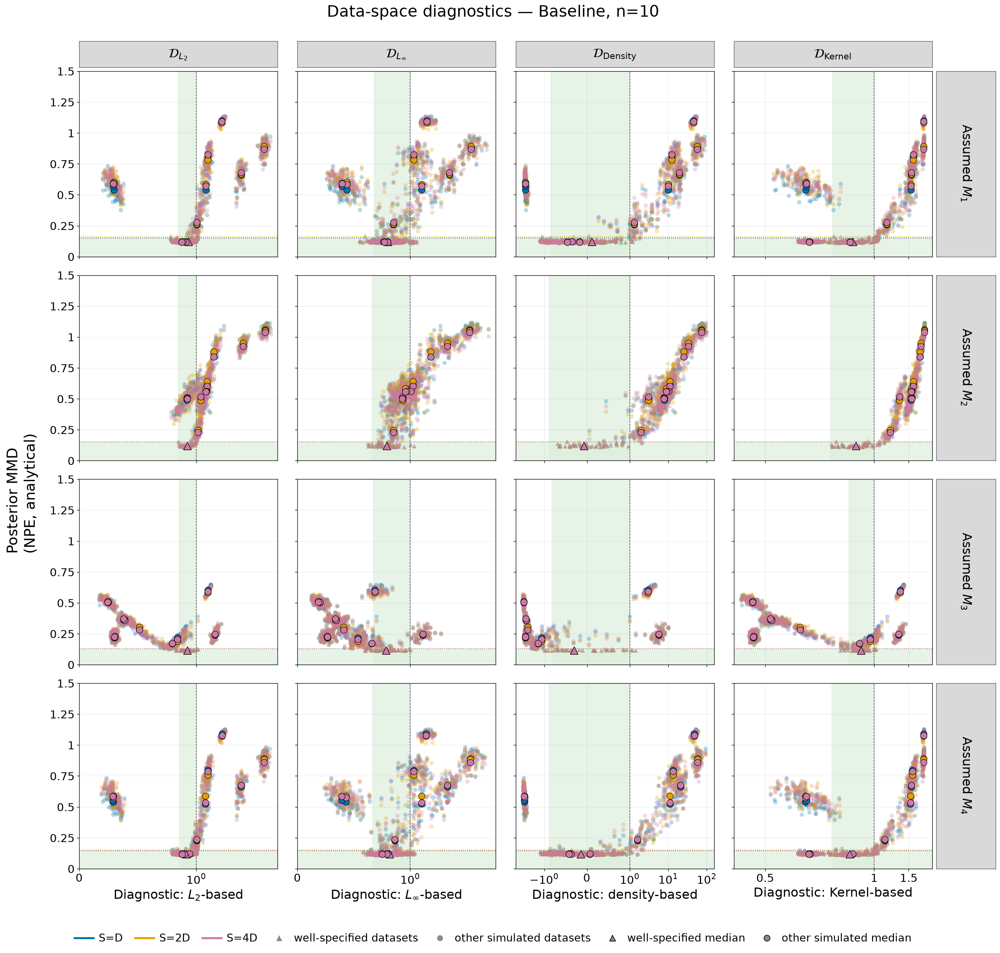

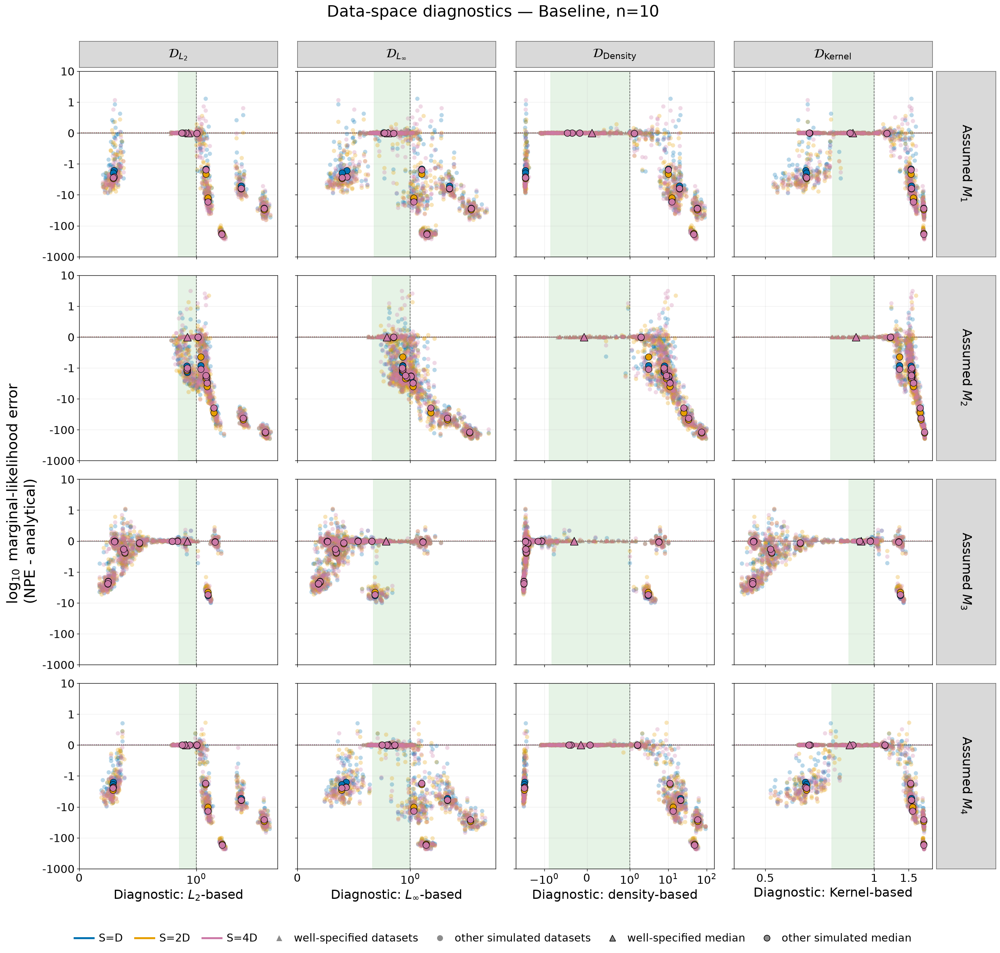

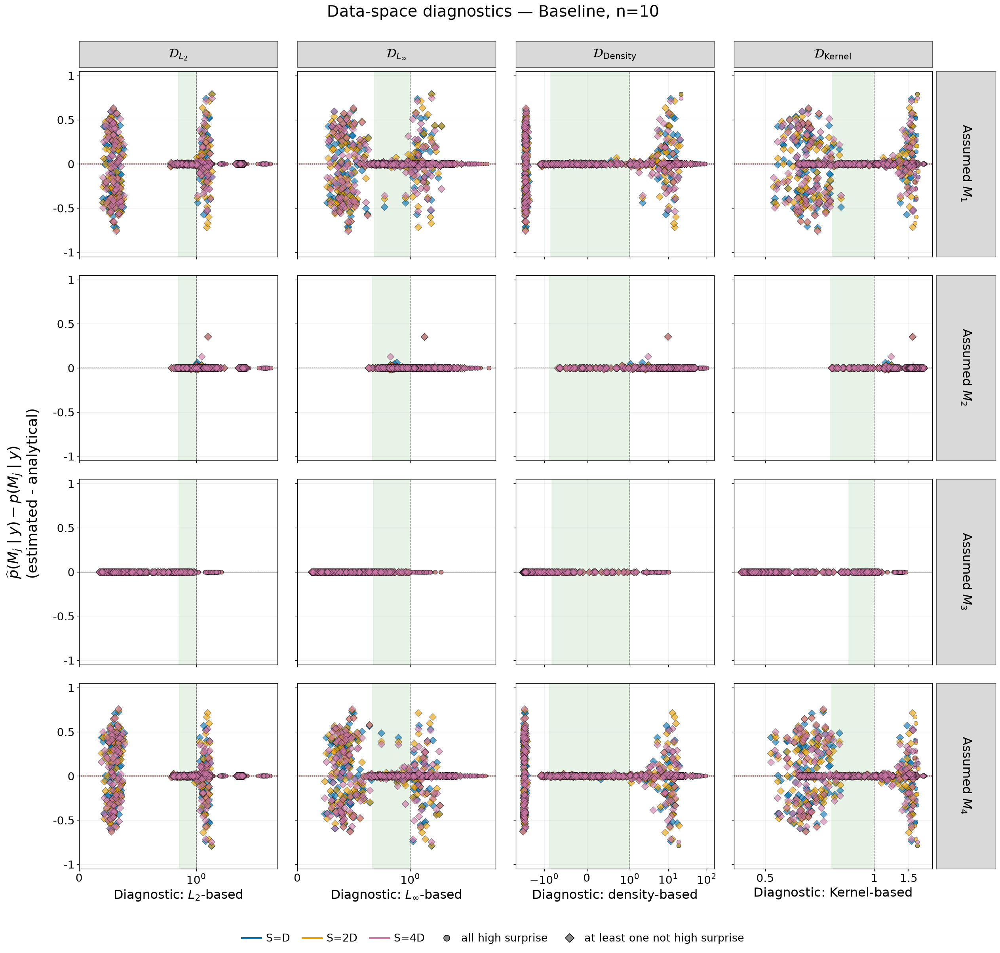

In [5]:
for metric in METRICS:
    show_overview("baseline", metric)


## Inference-only: data-space diagnostic overview

The same four diagnostics and three metrics, with S=40/80 selected from `SUMMARY_DIMS`.
Both settings share y-axis ranges while using their own saved errors and threshold lines.

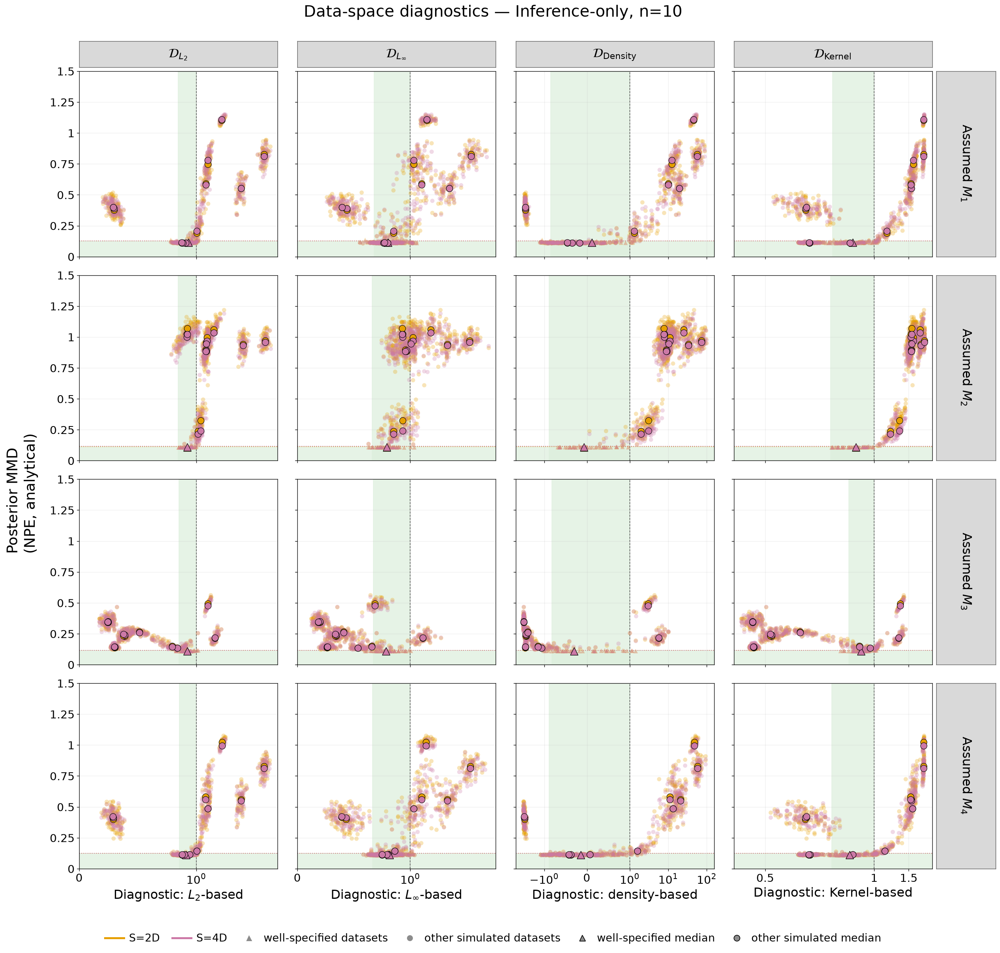

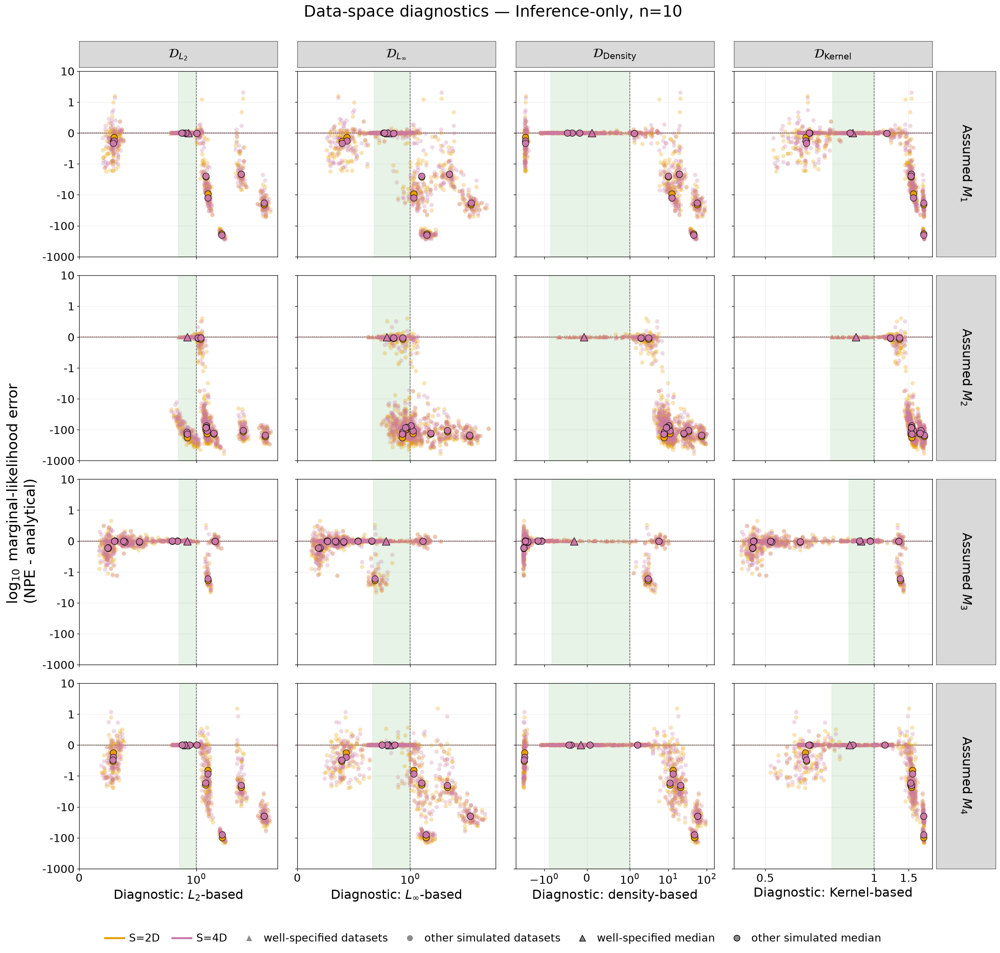

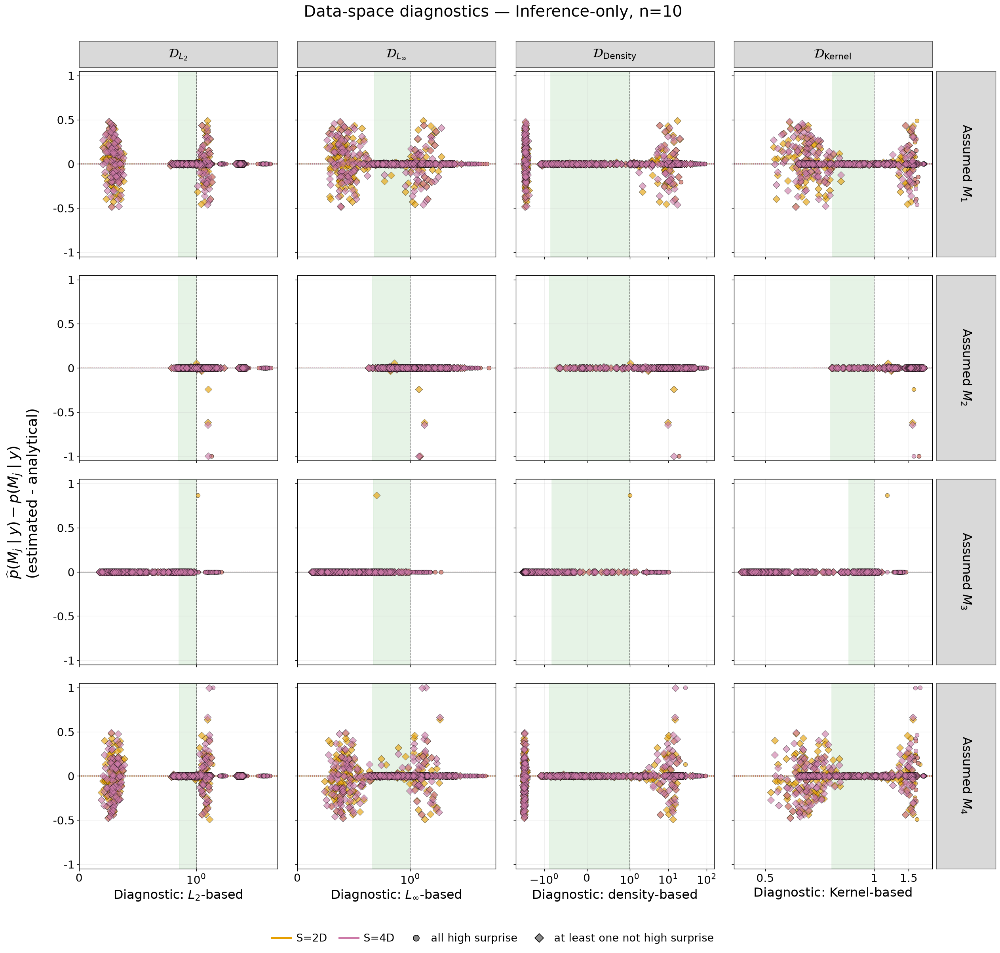

In [6]:
for metric in METRICS:
    show_overview("inference_only", metric)


## Data-space comparison by S and source model

Largest S first. Baseline is on the left and inference-only is on the right for S=80/40;
S=20 has baseline data only. Match the reference notebook's L2/Density columns,
M1–M12 source colors, and circle markers. All panels use data-space diagnostics.

### S=4D (S=80) — Baseline vs inference-only

#### Posterior MMD error

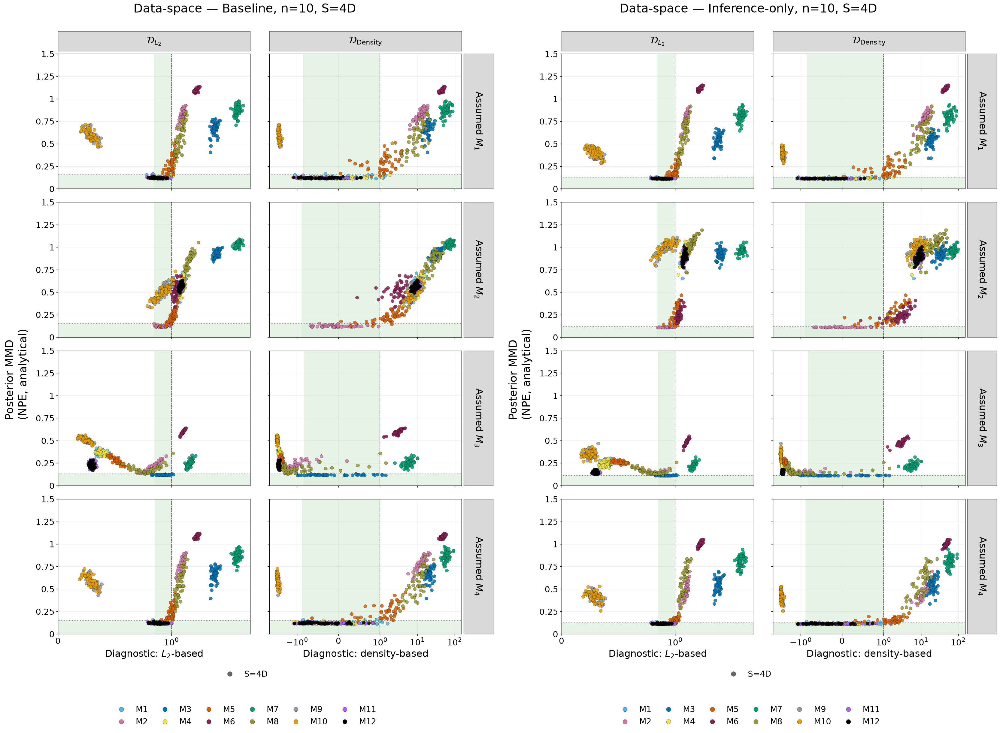

#### Log10 marginal-likelihood error

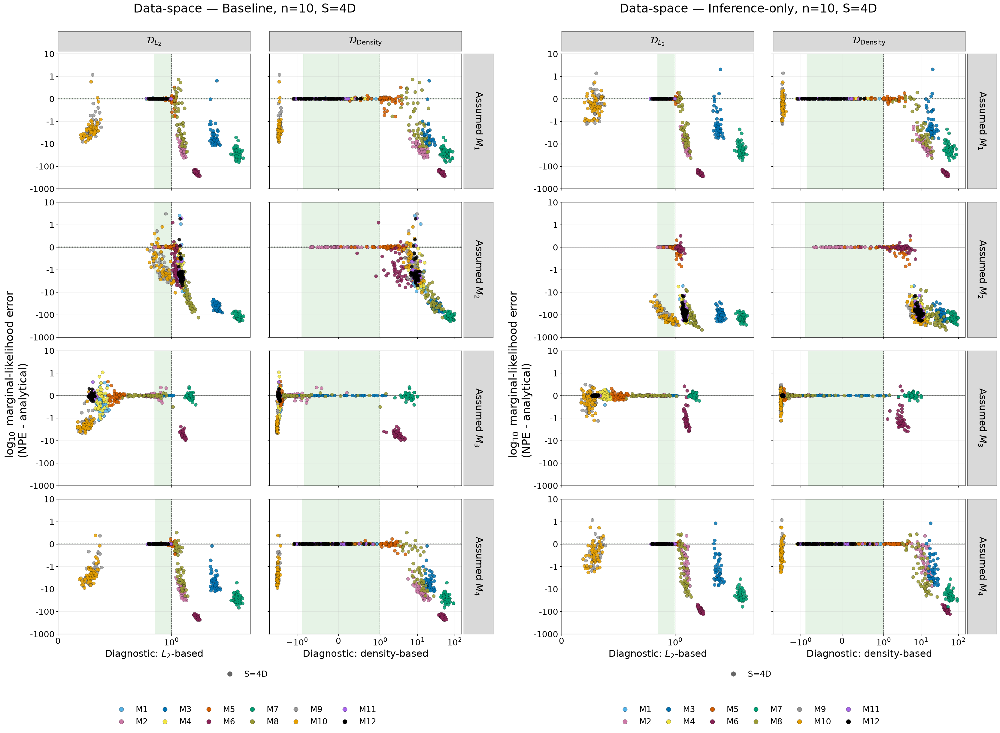

#### PMP error

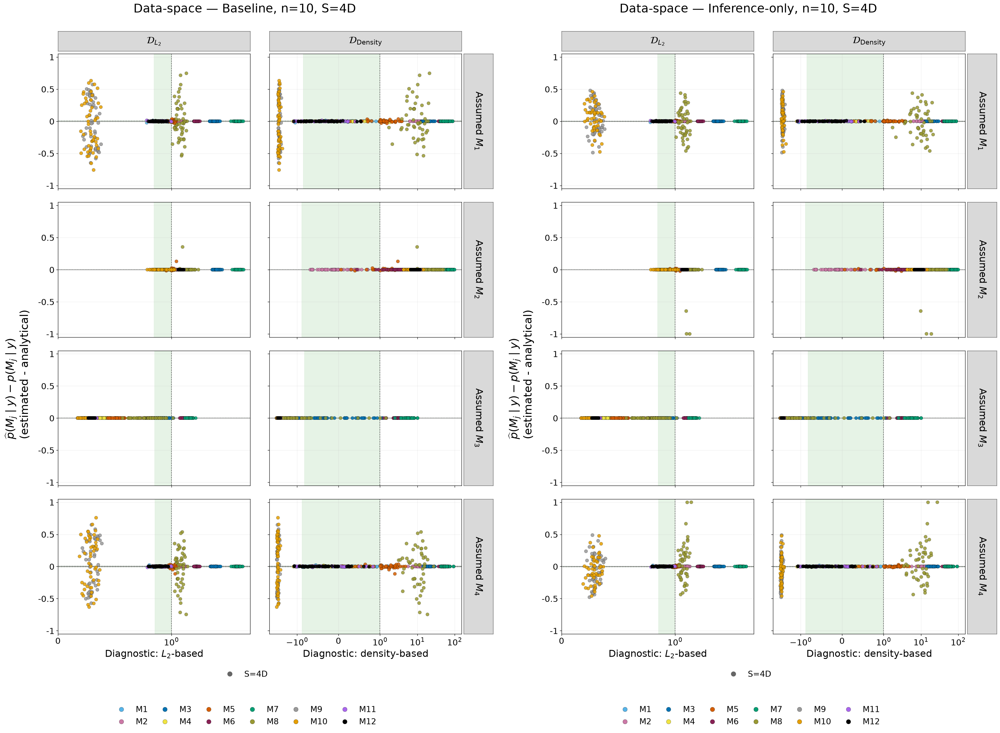

### S=2D (S=40) — Baseline vs inference-only

#### Posterior MMD error

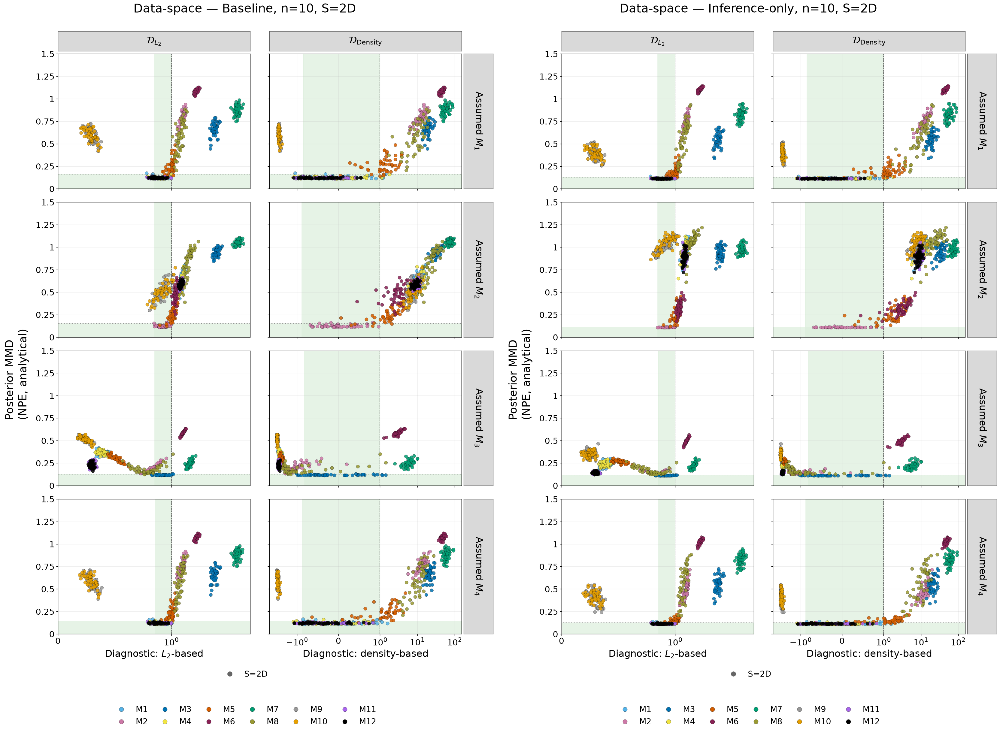

#### Log10 marginal-likelihood error

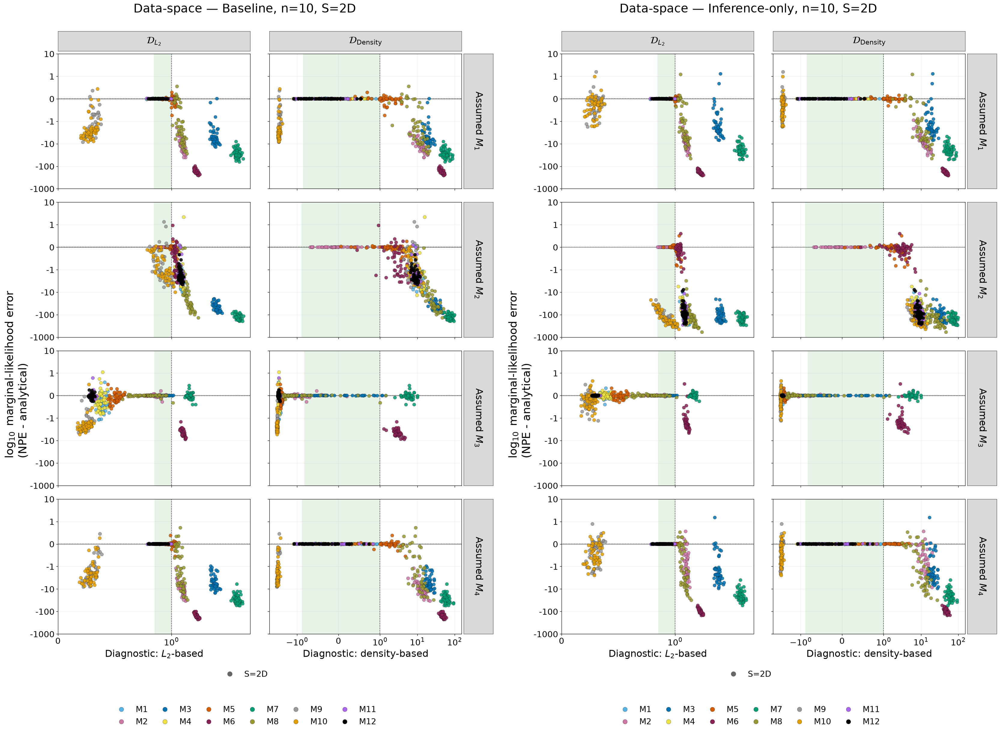

#### PMP error

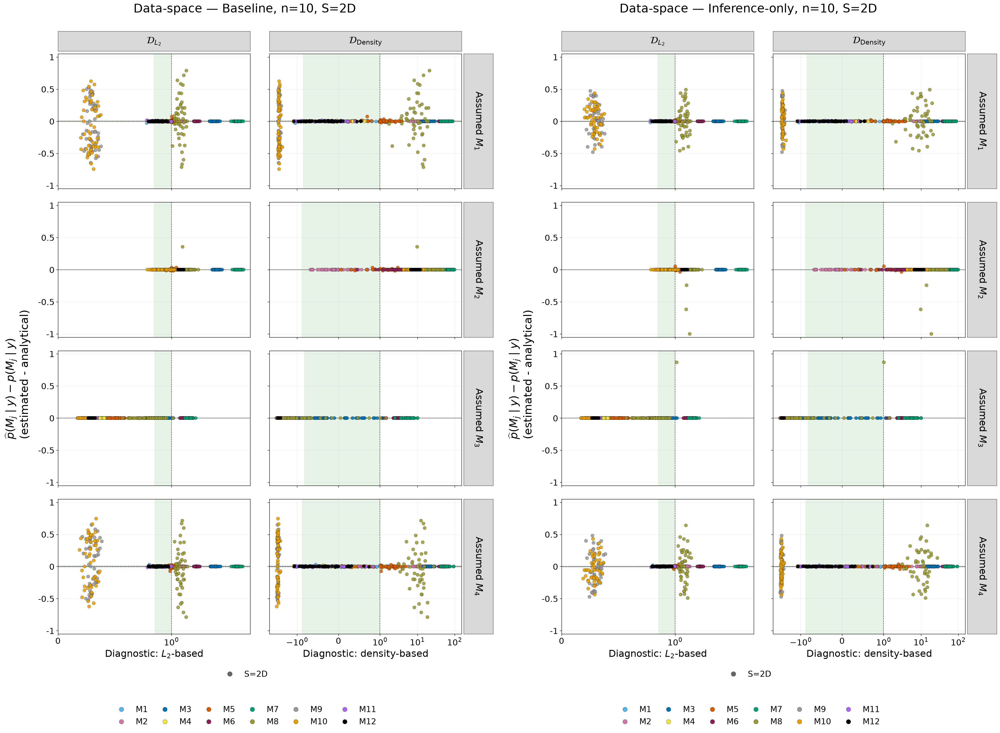

### S=D (S=20) — Baseline

#### Posterior MMD error

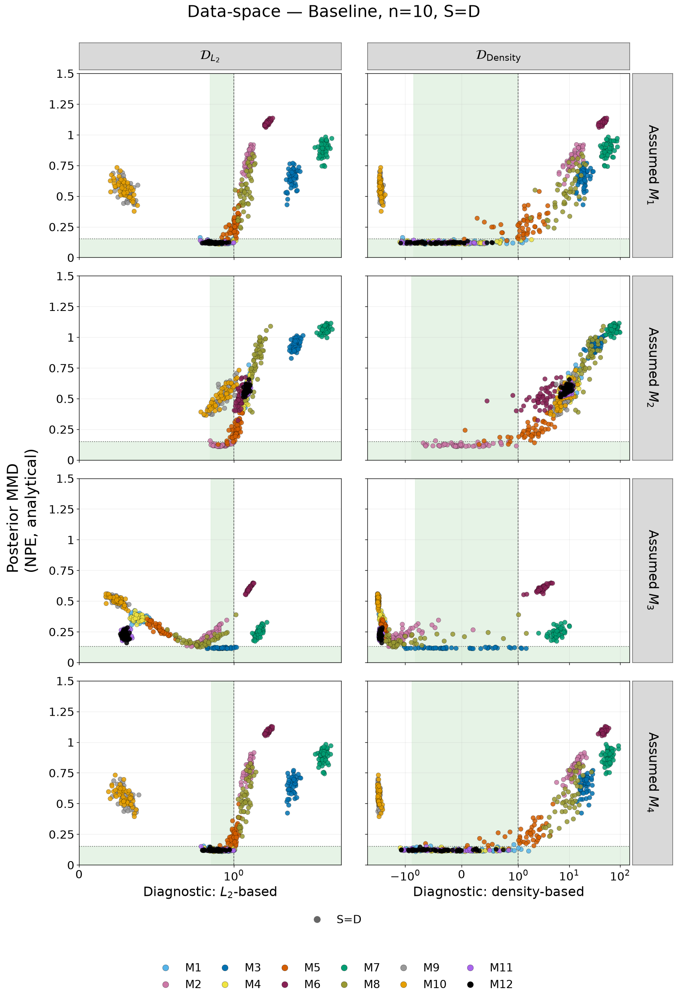

#### Log10 marginal-likelihood error

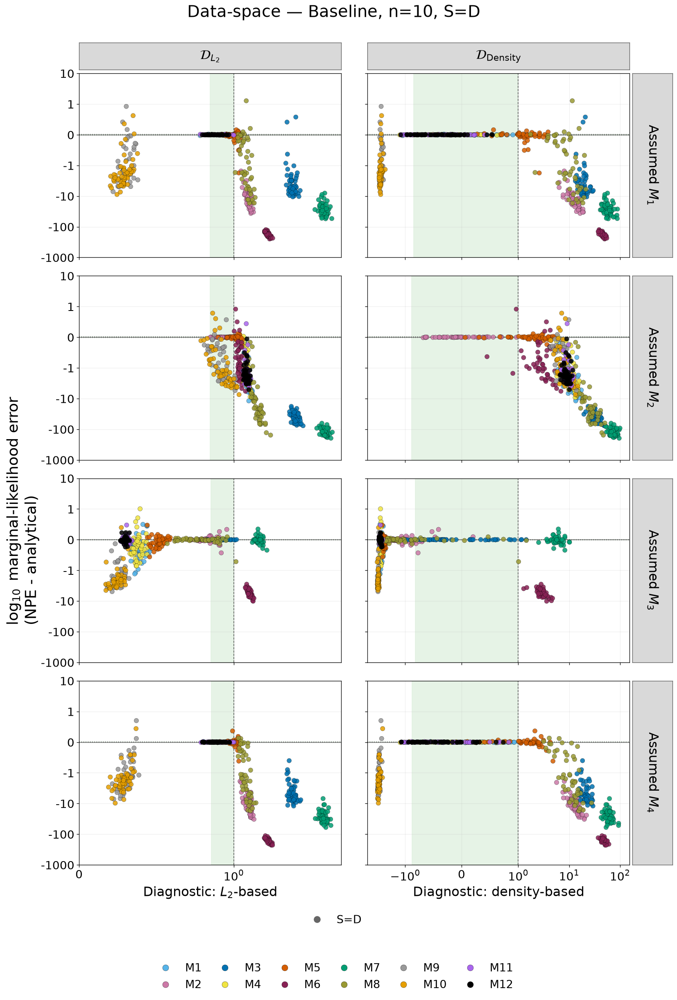

#### PMP error

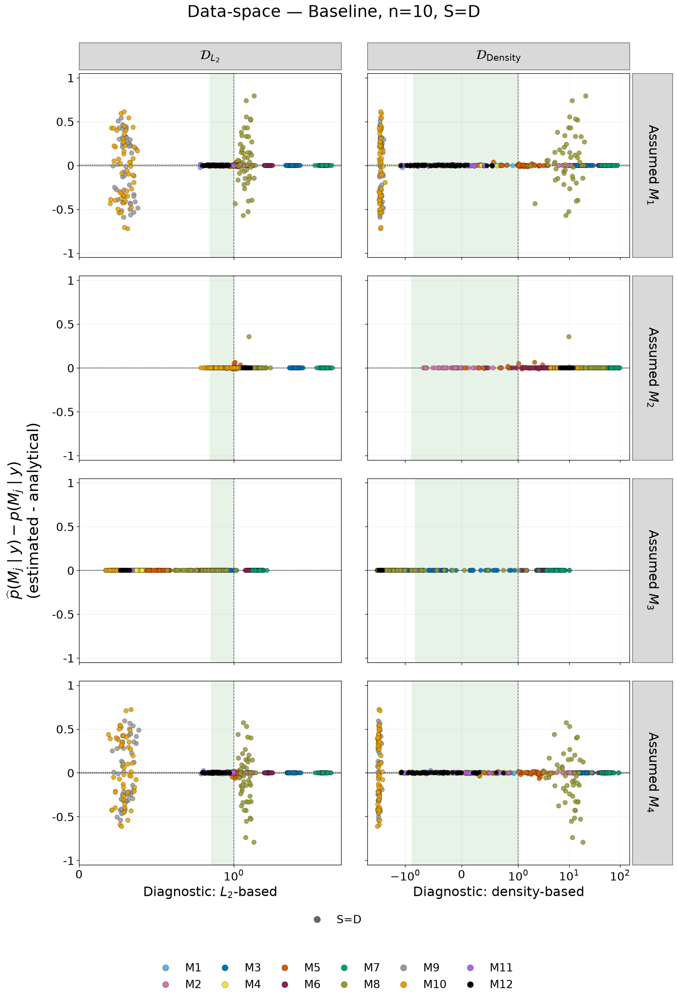

In [7]:
for summary_dim in SOURCE_SUMMARY_DIMS:
    label = next(label for label, frame in data_runs["baseline"].items()
                 if int(frame.summary_dim.iloc[0]) == summary_dim)
    paired = summary_dim in SUPPORTED[NUM_OBS, "inference_only"]
    suffix = "Baseline vs inference-only" if paired else "Baseline"
    display(Markdown(f"### {label} (S={summary_dim}) — {suffix}"))
    for metric in METRICS:
        display(Markdown(f"#### {METRIC_NAMES[metric]}"))
        if paired:
            show_source_comparison(metric, summary_dim)
        else:
            show_source_baseline(metric, summary_dim)
